# Ultra-Low SNR (−19 dB) Breakdown vs. LoRaSeek Neural Denoising

This notebook demonstrates on a real **SF7 LoRa chirp** ($BW = 125\text{ kHz}$, $F_s = 1\text{ MHz}$, $\text{SNR} = -19\text{ dB}$):
1. **Graph 1 — Ultra-Low SNR Breakdown (Raw Dechirp FFT at −19 dB):** True chirp energy is buried beneath random AWGN noise spikes, causing `argmax` to pick a false bin.
2. **Graph 2 — After LoRaSeek Denoiser (Denoised Dechirp FFT at −19 dB):** Passing the exact same noisy IQ frame through **`Spectrogram → LoRaSeek AI Noise Suppression → iSTFT → Dechirp FFT`** suppresses the noise floor and cleanly reveals the true symbol peak.
3. **Side-by-Side Comparison & STFT Spectrogram View:** Ready-to-drop 300 DPI figures saved under `Server/notebooks/figures/`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt

# Locate Server/ directory automatically regardless of current working directory
_cwd = Path.cwd().resolve()
SERVER_DIR = _cwd.parent if _cwd.name == "notebooks" else (_cwd / "Server" if (_cwd / "Server").exists() else _cwd)
if str(SERVER_DIR) not in sys.path:
    sys.path.insert(0, str(SERVER_DIR))

from utils.LoRa import LoRa
from utils import loraseek_inference

FIG_DIR = SERVER_DIR / "notebooks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ── Experiment Configuration ─────────────────────────────────────────────────
SF = 7
BW = 125_000
FS = 1_000_000
N_CLASSES = 2 ** SF           # 128 FFT bins
SNR_DB = -19.0
GT_SYMBOL = 42                # Ground-truth symbol bin
SEED = 144                    # Reproducible -19 dB AWGN seed
CKPT_NAME = "75000_LoRaSeek.pkl"

print(f"Server dir : {SERVER_DIR}")
print(f"Device     : {loraseek_inference.DEVICE}")
print(f"Config     : SF{SF}, BW={BW/1e3:.0f} kHz, Fs={FS/1e6:.0f} MHz, SNR={SNR_DB:.0f} dB, GT Symbol={GT_SYMBOL}, Seed={SEED}")

Server dir : C:\Users\priba\Sean-2025\INC-LAB\CRAN-implementation\Server
Device     : cpu
Config     : SF7, BW=125 kHz, Fs=1 MHz, SNR=-19 dB, GT Symbol=42, Seed=144


In [2]:
def dechirp_dual_band_fft(frame: np.ndarray, down_ref: np.ndarray, n_classes: int = 128) -> np.ndarray:
    """Full-rate dual-band folded dechirped FFT magnitude spectrum (matches helper_function.py)."""
    dechirped = frame * down_ref
    psd = np.abs(np.fft.fftshift(np.fft.fft(dechirped)))
    center = len(psd) // 2
    return psd[center : center + n_classes] + psd[center - n_classes : center]


def run_loraseek_pipeline(noisy_frame: np.ndarray, sf: int = 7, ckpt_name: str = "75000_LoRaSeek.pkl"):
    """
    Step-by-step LoRaSeek pipeline:
      Noisy IQ -> Hann STFT Spectrogram -> LoRaSeek AI Noise Suppression -> Full-Rate iSTFT -> Clean IQ
    Returns (denoised_iq, raw_spec_mag, denoised_spec_mag).
    """
    model = loraseek_inference._load_loraseek_model(ckpt_name, sf=sf)
    opts = loraseek_inference._LoRaSeekOptsSF7() if sf == 7 else loraseek_inference._LoRaSeekOptsSF8()
    device = loraseek_inference.DEVICE
    window = torch.hann_window(opts.stft_window, device=device)
    trim_size = opts.freq_size // 2
    nsamp = opts.stft_nfft

    with torch.no_grad():
        x_t = torch.from_numpy(noisy_frame[None, :].astype(np.complex64)).to(device)
        # 1. Spectrogram (STFT)
        raw_spec = torch.stft(
            input=x_t,
            n_fft=opts.stft_nfft,
            hop_length=opts.stft_overlap,
            win_length=opts.stft_window,
            window=window,
            pad_mode="constant",
            return_complex=True,
        )
        # Crop central 2^SF bandwidth bins & normalize
        y = torch.cat((raw_spec[:, -trim_size:, :], raw_spec[:, 0:trim_size, :]), dim=1)
        y_abs_max = torch.clamp(torch.amax(torch.abs(y), dim=(1, 2), keepdim=True), min=1e-8)
        y_norm = y / y_abs_max
        net_in = torch.view_as_real(y_norm).permute(0, 3, 1, 2).to(dtype=torch.float32)[:, :, :, :32]

        # 2. AI Noise Suppression (LoRaSeek Transformer + Dual-Attention U-Net)
        denoised_net = model(net_in)
        spec_complex = torch.complex(denoised_net[:, 0], denoised_net[:, 1])

        # 3. Full-rate Inverse STFT (iSTFT) back to time-domain IQ
        B, _, T = spec_complex.shape
        full_spec = torch.zeros((B, opts.stft_nfft, T), dtype=torch.complex64, device=device)
        full_spec[:, -trim_size:, :] = spec_complex[:, :trim_size, :]
        full_spec[:, :trim_size, :] = spec_complex[:, trim_size:, :]

        recon = torch.istft(
            full_spec,
            n_fft=opts.stft_nfft,
            hop_length=opts.stft_overlap,
            win_length=opts.stft_window,
            window=window,
            onesided=False,
            return_complex=True,
            center=True,
        )[0].cpu().numpy()

    if len(recon) < nsamp:
        recon = np.pad(recon, (0, nsamp - len(recon)))
    else:
        recon = recon[:nsamp]

    raw_spec_mag = torch.abs(y_norm[0, :, :32]).cpu().numpy()
    den_spec_mag = torch.abs(spec_complex[0]).cpu().numpy()
    return recon, raw_spec_mag, den_spec_mag


# ── Synthesize Exact -19 dB Chirp & Run Both Pipelines ───────────────────────
lora = LoRa(SF, BW)
down_ref = np.conj(lora.gen_symbol_fs(0, down=False, Fs=FS))
clean_chirp = lora.gen_symbol_fs(GT_SYMBOL, down=False, Fs=FS)
noisy_chirp = lora.awgn_iq_with_seed(clean_chirp, SNR_DB, seed=SEED)

# 1. Raw Dechirp FFT (No Denoising)
raw_fft = dechirp_dual_band_fft(noisy_chirp, down_ref, N_CLASSES)
raw_fft_norm = raw_fft / np.max(raw_fft)
raw_peak_bin = int(np.argmax(raw_fft))
raw_p2med = float(raw_fft[GT_SYMBOL] / np.median(raw_fft))

# 2. LoRaSeek Denoised Pipeline -> Dechirp FFT
denoised_iq, raw_spec_mag, den_spec_mag = run_loraseek_pipeline(noisy_chirp, sf=SF, ckpt_name=CKPT_NAME)
den_fft = dechirp_dual_band_fft(denoised_iq, down_ref, N_CLASSES)
den_fft_norm = den_fft / np.max(den_fft)
den_peak_bin = int(np.argmax(den_fft))
den_p2med = float(den_fft[GT_SYMBOL] / np.median(den_fft))

print("=== Experiment Summary (SF7, SNR = -19 dB) ===")
print(f"Ground-Truth Symbol Bin       : {GT_SYMBOL}")
print(f"[Raw Dechirp FFT]    argmax   : bin {raw_peak_bin}  ({'CORRECT' if raw_peak_bin == GT_SYMBOL else 'WRONG - False Noise Spike!'})")
print(f"                     true mag : {raw_fft_norm[GT_SYMBOL]:.3f} (Peak-to-Median Noise: {raw_p2med:.2f}x / {20*np.log10(raw_p2med):.1f} dB)")
print(f"[After LoRaSeek]     argmax   : bin {den_peak_bin}  ({'CORRECT - Peak Revealed!' if den_peak_bin == GT_SYMBOL else 'WRONG'})")
print(f"                     true mag : {den_fft_norm[GT_SYMBOL]:.3f} (Peak-to-Median Noise: {den_p2med:.2f}x / {20*np.log10(den_p2med):.1f} dB)")
print(f"Noise-Floor Suppression Gain  : +{20*np.log10(den_p2med / raw_p2med):.1f} dB ({den_p2med / raw_p2med:.1f}x improvement)")

=== Experiment Summary (SF7, SNR = -19 dB) ===
Ground-Truth Symbol Bin       : 42
[Raw Dechirp FFT]    argmax   : bin 101  (WRONG - False Noise Spike!)
                     true mag : 0.744 (Peak-to-Median Noise: 1.48x / 3.4 dB)
[After LoRaSeek]     argmax   : bin 42  (CORRECT - Peak Revealed!)
                     true mag : 1.000 (Peak-to-Median Noise: 29.84x / 29.5 dB)
Noise-Floor Suppression Gain  : +26.1 dB (20.1x improvement)


Saved Graph 1 -> C:\Users\priba\Sean-2025\INC-LAB\CRAN-implementation\Server\notebooks\figures\graph1_raw_fft_minus19db.png


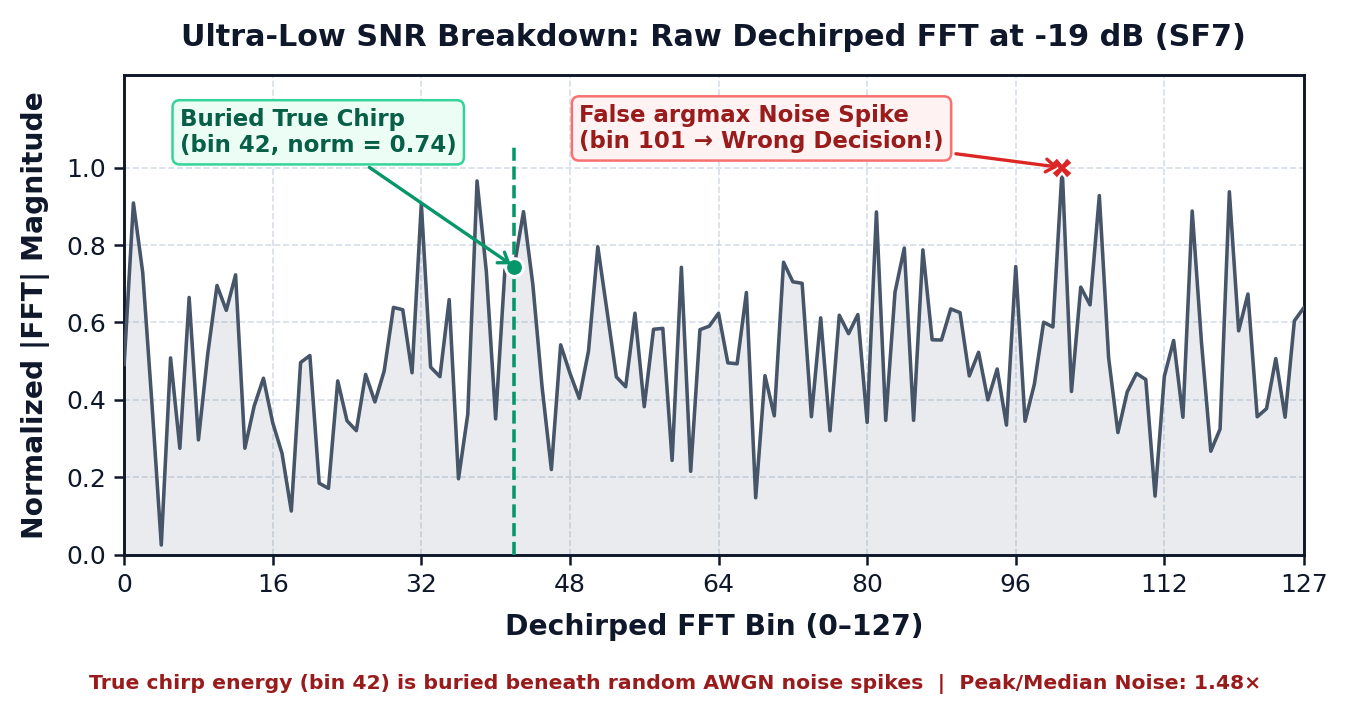

In [3]:
# ── Shared Journal-Grade Styling ─────────────────────────────────────────────
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Segoe UI"]
bins = np.arange(N_CLASSES)

def style_journal_ax(ax, xlabel="Dechirped FFT Bin (0–127)", ylabel="Normalized |FFT| Magnitude"):
    ax.set_facecolor("#ffffff")
    ax.set_xlim(0, N_CLASSES - 1)
    ax.set_ylim(0.0, 1.24)
    ax.set_xticks([0, 16, 32, 48, 64, 80, 96, 112, 127])
    ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.grid(True, linestyle="--", linewidth=0.8, color="#cbd5e1", alpha=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", labelsize=12, colors="#0f172a", width=1.2, length=5)
    ax.set_xlabel(xlabel, fontsize=13.5, fontweight="bold", color="#0f172a", labelpad=8)
    ax.set_ylabel(ylabel, fontsize=13.5, fontweight="bold", color="#0f172a", labelpad=8)
    for sp in ax.spines.values():
        sp.set_color("#0f172a")
        sp.set_linewidth(1.4)

# ══════════════════════════════════════════════════════════════════════════════
# GRAPH 1: Ultra-Low SNR Breakdown — Raw Dechirped FFT at -19 dB
# ══════════════════════════════════════════════════════════════════════════════
fig1, ax1 = plt.subplots(figsize=(9.0, 4.7), dpi=300, facecolor="#ffffff")
style_journal_ax(ax1)

ax1.plot(bins, raw_fft_norm, color="#475569", lw=1.7, zorder=3, label="Raw Dechirp FFT")
ax1.fill_between(bins, 0, raw_fft_norm, color="#64748b", alpha=0.14, zorder=2)

# Mark buried true symbol bin
ax1.plot([GT_SYMBOL, GT_SYMBOL], [0, 1.06], ls="--", color="#059669", lw=1.7, zorder=4)
ax1.plot(GT_SYMBOL, raw_fft_norm[GT_SYMBOL], "o", color="#059669", ms=8.5,
         markeredgecolor="#ffffff", markeredgewidth=1.4, zorder=6)
ax1.annotate(
    f"Buried True Chirp\n(bin {GT_SYMBOL}, norm = {raw_fft_norm[GT_SYMBOL]:.2f})",
    xy=(GT_SYMBOL, raw_fft_norm[GT_SYMBOL]),
    xytext=(GT_SYMBOL - 36, 1.04),
    fontsize=11, fontweight="bold", color="#065f46",
    bbox=dict(boxstyle="round,pad=0.32", fc="#ecfdf5", ec="#34d399", lw=1.2),
    arrowprops=dict(arrowstyle="->,head_width=0.28", color="#059669", lw=1.6),
    zorder=8,
)

# Mark false AWGN noise spike selected by argmax
ax1.plot(raw_peak_bin, raw_fft_norm[raw_peak_bin], "X", color="#dc2626", ms=10.5,
         markeredgecolor="#ffffff", markeredgewidth=1.1, zorder=7)
ax1.annotate(
    f"False argmax Noise Spike\n(bin {raw_peak_bin} → Wrong Decision!)",
    xy=(raw_peak_bin, raw_fft_norm[raw_peak_bin]),
    xytext=(raw_peak_bin - 52, 1.05),
    fontsize=11, fontweight="bold", color="#991b1b",
    bbox=dict(boxstyle="round,pad=0.32", fc="#fef2f2", ec="#f87171", lw=1.2),
    arrowprops=dict(arrowstyle="->,head_width=0.28", color="#dc2626", lw=1.6),
    zorder=8,
)

ax1.set_title(
    f"Ultra-Low SNR Breakdown: Raw Dechirped FFT at {SNR_DB:.0f} dB (SF{SF})",
    fontsize=14.5, fontweight="bold", color="#0f172a", pad=14,
)
fig1.text(
    0.5, 0.022,
    f"True chirp energy (bin {GT_SYMBOL}) is buried beneath random AWGN noise spikes  |  Peak/Median Noise: {raw_p2med:.2f}×",
    ha="center", fontsize=9.8, fontweight="semibold", color="#991b1b",
)
fig1.tight_layout(rect=[0, 0.06, 1, 1])

out1 = FIG_DIR / "graph1_raw_fft_minus19db.png"
fig1.savefig(out1, dpi=300, facecolor="#ffffff")
print(f"Saved Graph 1 -> {out1}")
plt.show()

Saved Graph 2 -> C:\Users\priba\Sean-2025\INC-LAB\CRAN-implementation\Server\notebooks\figures\graph2_loraseek_denoised_fft_minus19db.png


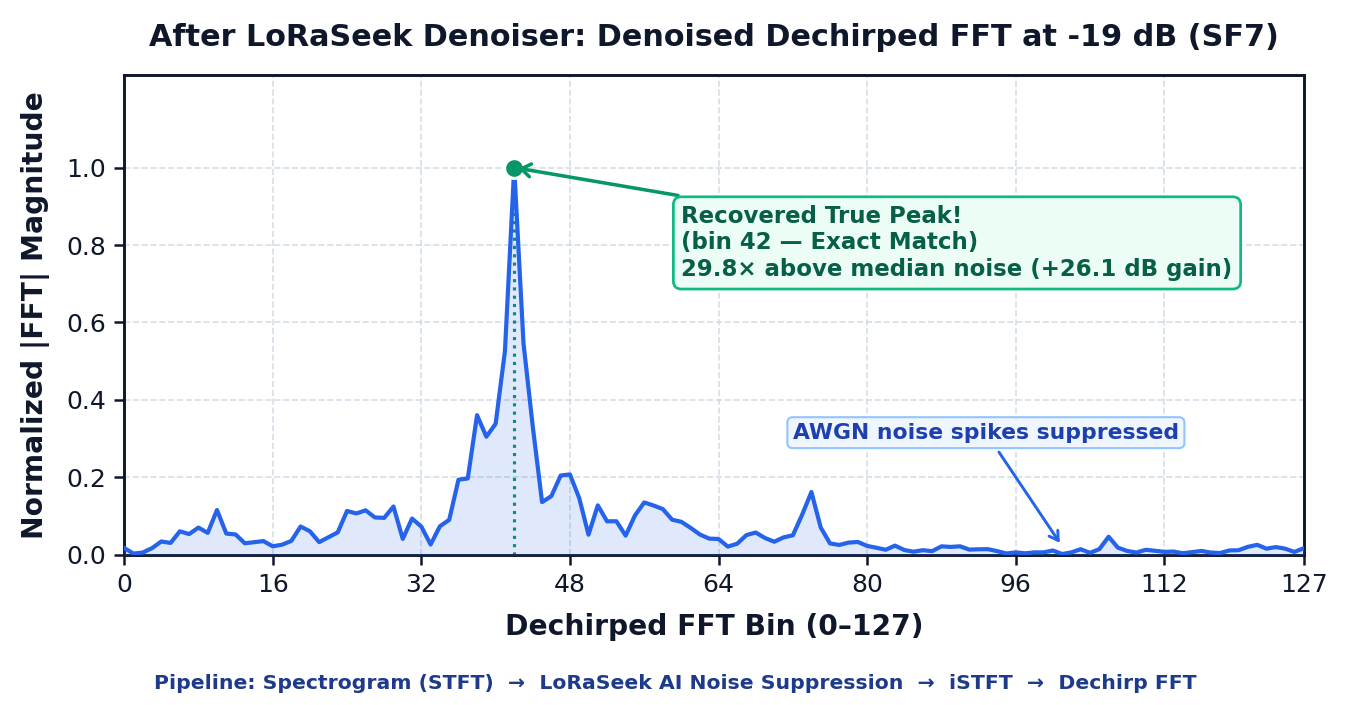

In [4]:
# ══════════════════════════════════════════════════════════════════════════════
# GRAPH 2: After LoRaSeek Denoiser — Denoised Dechirped FFT at -19 dB
# ══════════════════════════════════════════════════════════════════════════════
fig2, ax2 = plt.subplots(figsize=(9.0, 4.7), dpi=300, facecolor="#ffffff")
style_journal_ax(ax2)

ax2.plot(bins, den_fft_norm, color="#2563eb", lw=2.0, zorder=4, label="LoRaSeek Denoised FFT")
ax2.fill_between(bins, 0, den_fft_norm, color="#2563eb", alpha=0.14, zorder=3)

# Mark recovered true symbol peak
ax2.plot([GT_SYMBOL, GT_SYMBOL], [0, 1.0], ls=":", color="#059669", lw=1.5, zorder=2)
ax2.plot(den_peak_bin, den_fft_norm[den_peak_bin], "o", color="#059669", ms=9.5,
         markeredgecolor="#ffffff", markeredgewidth=1.5, zorder=6)
ax2.annotate(
    f"Recovered True Peak!\n(bin {den_peak_bin} — Exact Match)\n{den_p2med:.1f}× above median noise (+{20*np.log10(den_p2med/raw_p2med):.1f} dB gain)",
    xy=(den_peak_bin, den_fft_norm[den_peak_bin]),
    xytext=(den_peak_bin + 18, 0.72),
    fontsize=11, fontweight="bold", color="#065f46",
    bbox=dict(boxstyle="round,pad=0.35", fc="#ecfdf5", ec="#10b981", lw=1.3),
    arrowprops=dict(arrowstyle="->,head_width=0.28", color="#059669", lw=1.7),
    zorder=8,
)

# Subtle callout showing suppressed noise floor
ax2.annotate(
    "AWGN noise spikes suppressed",
    xy=(101, den_fft_norm[101] + 0.02),
    xytext=(72, 0.30),
    fontsize=10.5, fontweight="bold", color="#1e40af",
    bbox=dict(boxstyle="round,pad=0.25", fc="#eff6ff", ec="#93c5fd", lw=1.0),
    arrowprops=dict(arrowstyle="->,head_width=0.24", color="#2563eb", lw=1.4),
    zorder=8,
)

ax2.set_title(
    f"After LoRaSeek Denoiser: Denoised Dechirped FFT at {SNR_DB:.0f} dB (SF{SF})",
    fontsize=14.5, fontweight="bold", color="#0f172a", pad=14,
)
fig2.text(
    0.5, 0.022,
    "Pipeline: Spectrogram (STFT)  →  LoRaSeek AI Noise Suppression  →  iSTFT  →  Dechirp FFT",
    ha="center", fontsize=9.8, fontweight="semibold", color="#1e3a8a",
)
fig2.tight_layout(rect=[0, 0.06, 1, 1])

out2 = FIG_DIR / "graph2_loraseek_denoised_fft_minus19db.png"
fig2.savefig(out2, dpi=300, facecolor="#ffffff")
print(f"Saved Graph 2 -> {out2}")
plt.show()

Saved Combined Side-by-Side Figure -> C:\Users\priba\Sean-2025\INC-LAB\CRAN-implementation\Server\notebooks\figures\combined_raw_vs_loraseek_minus19db.png


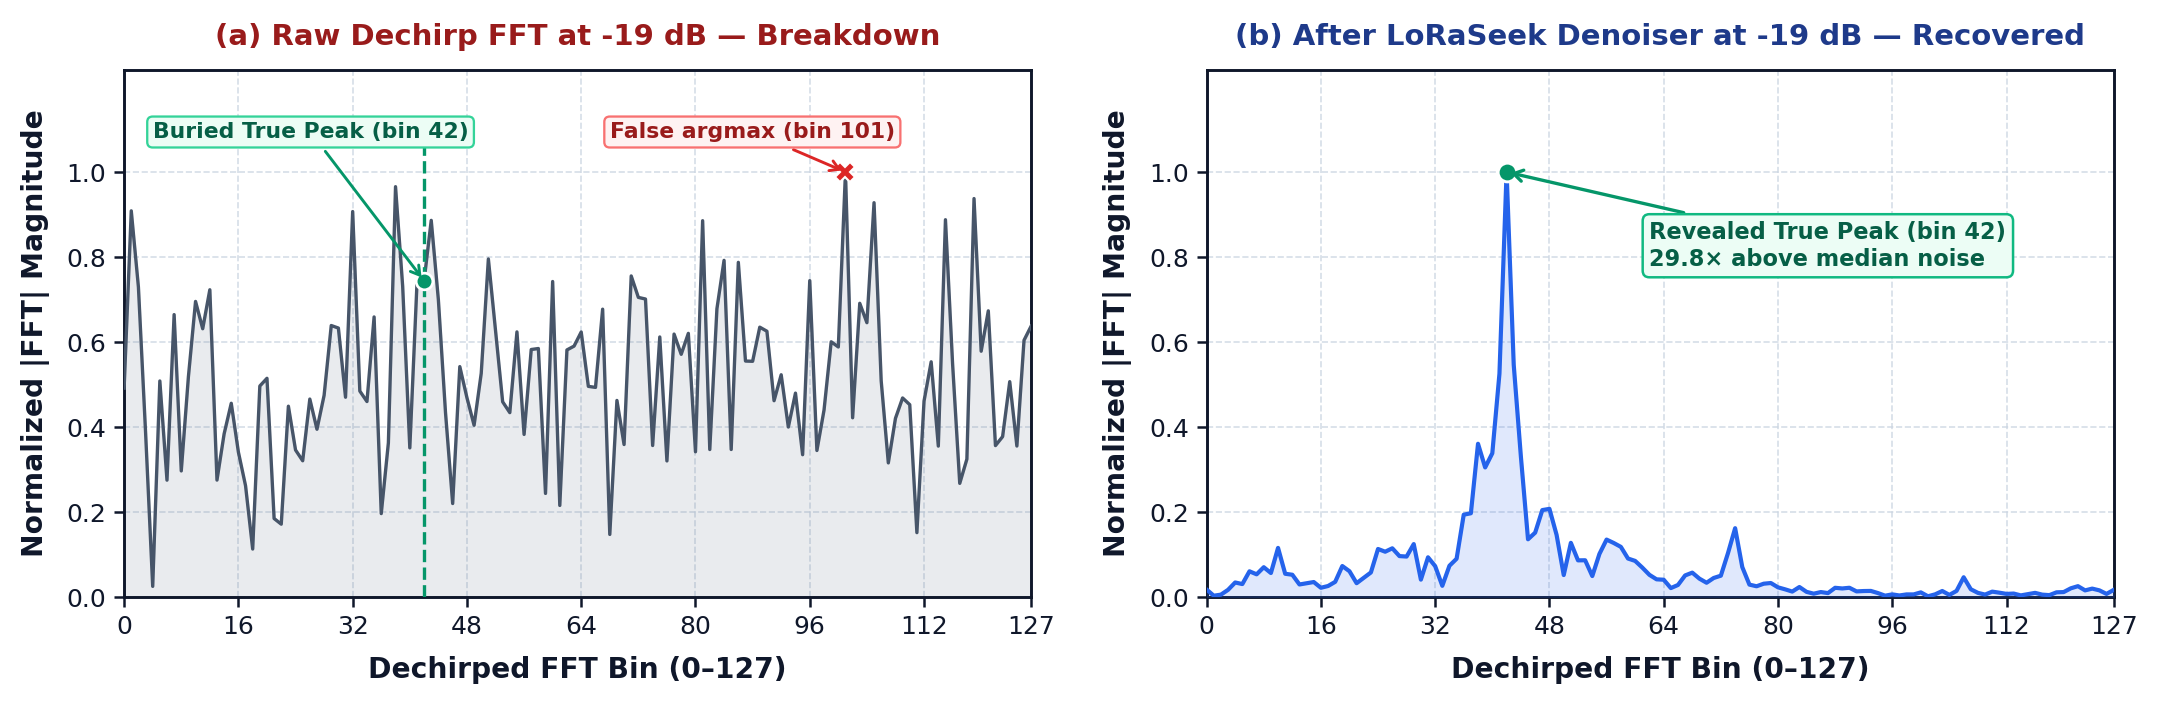

In [5]:
# ══════════════════════════════════════════════════════════════════════════════
# BONUS: Side-by-Side PPT Comparison (Raw vs. LoRaSeek Denoised at -19 dB)
# ══════════════════════════════════════════════════════════════════════════════
fig3, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(14.4, 4.7), dpi=300, facecolor="#ffffff")

# Left: Raw Breakdown
style_journal_ax(ax_l)
ax_l.plot(bins, raw_fft_norm, color="#475569", lw=1.6, zorder=3)
ax_l.fill_between(bins, 0, raw_fft_norm, color="#64748b", alpha=0.14, zorder=2)
ax_l.plot([GT_SYMBOL, GT_SYMBOL], [0, 1.06], ls="--", color="#059669", lw=1.6, zorder=4)
ax_l.plot(GT_SYMBOL, raw_fft_norm[GT_SYMBOL], "o", color="#059669", ms=8.0,
          markeredgecolor="#ffffff", markeredgewidth=1.3, zorder=6)
ax_l.plot(raw_peak_bin, raw_fft_norm[raw_peak_bin], "X", color="#dc2626", ms=10.0,
          markeredgecolor="#ffffff", markeredgewidth=1.0, zorder=7)
ax_l.annotate(
    f"Buried True Peak (bin {GT_SYMBOL})",
    xy=(GT_SYMBOL, raw_fft_norm[GT_SYMBOL]), xytext=(4, 1.08),
    fontsize=10.5, fontweight="bold", color="#065f46",
    bbox=dict(boxstyle="round,pad=0.25", fc="#ecfdf5", ec="#34d399", lw=1.1),
    arrowprops=dict(arrowstyle="->,head_width=0.24", color="#059669", lw=1.4), zorder=8,
)
ax_l.annotate(
    f"False argmax (bin {raw_peak_bin})",
    xy=(raw_peak_bin, raw_fft_norm[raw_peak_bin]), xytext=(68, 1.08),
    fontsize=10.5, fontweight="bold", color="#991b1b",
    bbox=dict(boxstyle="round,pad=0.25", fc="#fef2f2", ec="#f87171", lw=1.1),
    arrowprops=dict(arrowstyle="->,head_width=0.24", color="#dc2626", lw=1.4), zorder=8,
)
ax_l.set_title(f"(a) Raw Dechirp FFT at {SNR_DB:.0f} dB — Breakdown", fontsize=14, fontweight="bold", color="#991b1b", pad=12)

# Right: After LoRaSeek
style_journal_ax(ax_r)
ax_r.plot(bins, den_fft_norm, color="#2563eb", lw=2.0, zorder=4)
ax_r.fill_between(bins, 0, den_fft_norm, color="#2563eb", alpha=0.14, zorder=3)
ax_r.plot(den_peak_bin, den_fft_norm[den_peak_bin], "o", color="#059669", ms=9.0,
          markeredgecolor="#ffffff", markeredgewidth=1.4, zorder=6)
ax_r.annotate(
    f"Revealed True Peak (bin {den_peak_bin})\n{den_p2med:.1f}× above median noise",
    xy=(den_peak_bin, den_fft_norm[den_peak_bin]), xytext=(62, 0.78),
    fontsize=10.8, fontweight="bold", color="#065f46",
    bbox=dict(boxstyle="round,pad=0.30", fc="#ecfdf5", ec="#10b981", lw=1.2),
    arrowprops=dict(arrowstyle="->,head_width=0.25", color="#059669", lw=1.6), zorder=8,
)
ax_r.set_title(f"(b) After LoRaSeek Denoiser at {SNR_DB:.0f} dB — Recovered", fontsize=14, fontweight="bold", color="#1e3a8a", pad=12)

fig3.tight_layout(w_pad=2.4)
out3 = FIG_DIR / "combined_raw_vs_loraseek_minus19db.png"
fig3.savefig(out3, dpi=300, facecolor="#ffffff")
print(f"Saved Combined Side-by-Side Figure -> {out3}")
plt.show()